In [43]:
import torch
import matplotlib.pyplot as plt
torch.manual_seed(45)


In [44]:
def generate_regression_data(n_objects, n_columns):
    #Ваги, які будемо навчати
    w = torch.zeros(n_columns)

    #Справжні ваги
    w_true = torch.normal(0,1, size=(n_columns, ))

    #Дані які буде приймати наша модель і робити передбачення
    X = torch.empty(size=(n_objects, n_columns)).uniform_(-7, 7)

    Y = torch.matmul(X, w_true) + torch.normal(0, 0.5, size=(n_objects, ))

    return X, Y, w_true, w

def mse_error(y_true, y_pred):
    #Середньоквадратична помилка для вирахування
    return torch.mean((y_true - y_pred)**2)

def l2_norm(new_w, w):
    #Функція для знаходження дистанції між минулими і теперешніми вагами
    diff = new_w - w
    squarred_diff = diff ** 2
    sum_of_squares = torch.sum(squarred_diff)
    l2_norm = torch.sqrt(sum_of_squares)

    return l2_norm

def gradient_descent(X, Y, w_true, w, eta, max_iter, min_weight_dist, display_every=None):
    #Навчання моделі шляхом градієнтного спуску

    #Ініціалізуємо дистанцію між вагами
    weight_dist = torch.inf
    iter = 0

    errors = []

    w_storage = w.clone().detach().unsqueeze(0)


    while weight_dist > min_weight_dist and iter < max_iter:

        y_pred = torch.matmul(X, w)

        dQ = 2 / Y.shape[0] * torch.matmul(X.T, y_pred - Y)

        new_w = w - (dQ * eta)

        weight_dist = l2_norm(new_w, w)

        error = mse_error(Y, y_pred)

        w = new_w
        iter += 1

        errors.append(error.item())
        w_storage = torch.concat([w_storage, new_w.unsqueeze(0)], dim=0)

        if display_every is not None and iter % display_every == 0:
            print(f"iter: {iter} | weights: {new_w} | error: {error}")

    return w, w_storage, errors

def plot_charts(w_true, w_storage, errors):
    fig, ax = plt.subplots(1, 2, figsize=(10,3))

    ax[0].scatter(w_storage[:, 0], w_storage[:, 1])
    ax[0].plot(w_storage[:, 0], w_storage[:, 1])
    ax[0].scatter(w_true[0], w_true[1])
    ax[0].set_title("Gradient Descent")

    ax[1].plot(errors)
    ax[1].set_title("Error")

    plt.tight_layout()
    plt.show()

iter: 10 | weights: tensor([-0.3106,  0.0140, -0.1883]) | error: 15.580127716064453
iter: 20 | weights: tensor([-0.5352,  0.0226, -0.3243]) | error: 8.268596649169922
iter: 30 | weights: tensor([-0.6977,  0.0278, -0.4226]) | error: 4.447135925292969
iter: 40 | weights: tensor([-0.8152,  0.0307, -0.4936]) | error: 2.4495370388031006
iter: 50 | weights: tensor([-0.9002,  0.0322, -0.5448]) | error: 1.4051933288574219
iter: 60 | weights: tensor([-0.9617,  0.0330, -0.5819]) | error: 0.8591399788856506
iter: 70 | weights: tensor([-1.0062,  0.0332, -0.6086]) | error: 0.573590874671936
iter: 80 | weights: tensor([-1.0384,  0.0332, -0.6280]) | error: 0.4242487847805023
iter: 90 | weights: tensor([-1.0617,  0.0330, -0.6419]) | error: 0.3461335003376007
iter: 100 | weights: tensor([-1.0786,  0.0328, -0.6520]) | error: 0.30526915192604065


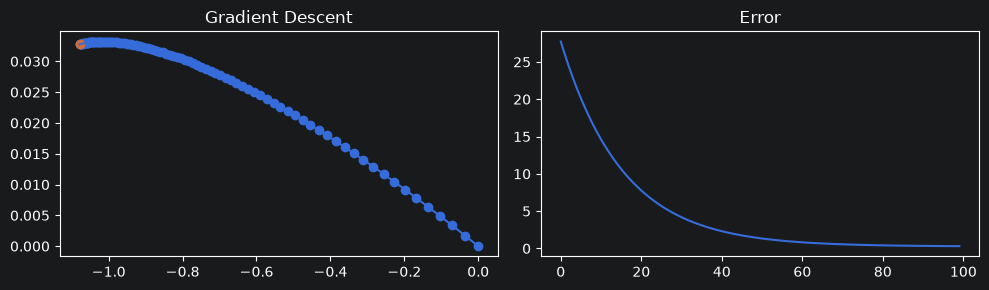

In [45]:
X, Y, w_true, w = generate_regression_data(n_objects=3000, n_columns=3)

w, w_storage, errors = gradient_descent(
    X, Y, w_true, w, eta=1e-3, max_iter=100, min_weight_dist=1e-8, display_every=10)

plot_charts(w, w_storage, errors)

In [55]:
def stochastic_gradient_descent(
    X, Y, w_true, w, eta, max_iter, min_weight_dist, display_every=None
):
    # Стохастичний градієнтний спуск (SGD)

    weight_dist = torch.inf
    iteration = 0

    # Зберігаємо історію помилок
    errors = []

    # Зберігаємо історію зміни ваг
    w_storage = w.clone().detach().unsqueeze(0)

    while weight_dist > min_weight_dist and iteration < max_iter:

        # Випадково вибираємо один об'єкт із датасету
        random_index = torch.randint(0, X.shape[0], size=(1, )).item()

        # Беремо тільки один об'єкт і його правильну відповідь
        x_random = X[random_index]
        y_random = Y[random_index]

        # Робимо передбачення тільки для цього об'єкта
        y_pred_random = x_random * w

        # Обчислюємо градієнт за одним випадковим об'єктом
        dQ = 2 * x_random * (y_pred_random - y_random)

        # Оновлюємо ваги за допомогою градієнта
        new_w = w - (eta * dQ)

        # Обчислюємо відстань між старими і новими вагами
        weight_dist = l2_norm(new_w, w)

        # Обчислюємо загальну помилку моделі
        error = mse_error(Y, torch.matmul(X, w))

        # Оновлюємо ваги
        w = new_w

        # Зберігаємо помилку
        errors.append(error.item())

        # Зберігаємо нові ваги
        w_storage = torch.cat(
            [w_storage, new_w.unsqueeze(0)], dim=0
        )

        iteration += 1

        # Виводимо результат кожні display_every ітерацій
        if display_every is not None and iteration % display_every == 0:
            print(
                f"iter: {iteration} | "
                f"weights: {new_w} | "
                f"error: {error.item()}"
            )

    return w, w_storage, errors

iter: 10 | weights: tensor([ 0.1450, -0.1217,  0.1263]) | error: 5.84049654006958
iter: 20 | weights: tensor([ 0.2361, -0.1872,  0.0312]) | error: 3.929022789001465
iter: 30 | weights: tensor([ 0.3831, -0.2605,  0.1039]) | error: 2.231135368347168
iter: 40 | weights: tensor([ 0.3930, -0.2237,  0.1073]) | error: 2.0299019813537598
iter: 50 | weights: tensor([ 0.5292, -0.3697,  0.0761]) | error: 0.8326430916786194
iter: 60 | weights: tensor([ 0.4846, -0.3179, -0.0168]) | error: 1.103010654449463
iter: 70 | weights: tensor([ 0.5044, -0.3350,  0.0687]) | error: 0.8733932971954346
iter: 80 | weights: tensor([ 0.5063, -0.2446,  0.0495]) | error: 0.9258581399917603
iter: 90 | weights: tensor([ 0.5355, -0.2443,  0.0826]) | error: 0.9864941239356995
iter: 100 | weights: tensor([ 0.6396, -0.3532,  0.2409]) | error: 0.5703362226486206


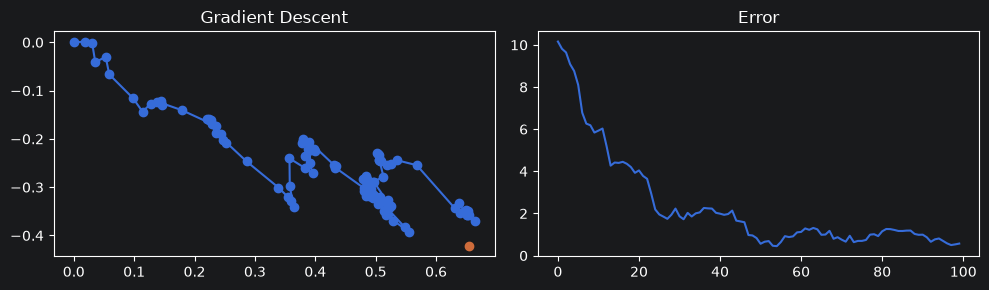

In [60]:
# Генеруємо дані
X, Y, w_true, w = generate_regression_data(
    n_objects=3000,
    n_columns=3
)

# Запускаємо стохастичний градієнтний спуск
w, w_storage, errors = stochastic_gradient_descent(
    X, Y, w_true, w,
    eta=1e-3,
    max_iter=100,
    min_weight_dist=1e-8,
    display_every=10
)

# Будуємо графіки
plot_charts(w_true, w_storage, errors)